# 🧪 Lab 1 — Introduction, Image Formation & Camera Geometry

| | |
|---|---|
| **Sessions** | 1 – 5 (Intro to CV · Image formation · Pinhole camera · Camera geometry & calibration) |
| **Weeks** | 1 – 2 |
| **Learning Outcomes** | **LO 1.1** Pinhole camera model & image formation · **LO 1.2** Camera geometry & calibration |
| **Type** | Practice assignment — do it **before** your Lab workshop (Session 5) |
| **Where to submit** | This notebook (`Lab1_Image_Formation_and_Camera_Geometry.ipynb`) on Canvas |
| **Estimated time** | 90 – 120 minutes |

---

### 🎯 Objectives
By the end of this lab you will be able to:
1. Prepare a working **Python + OpenCV environment** for a computer-vision project.
2. Treat an image as a **2-D numeric array** and manipulate it (brightness, inversion, channels).
3. Reproduce the **pinhole camera / perspective projection** math $x=f\frac{X}{Z}$ and explain its effects (size scaling, vanishing points, inversion).
4. Combine the **extrinsic** $[R\mid t]$ and **intrinsic** $K$ matrices into the full projection $\mathbf{x}=K\,[R\mid t]\,\mathbf{X}$.
5. Run a **camera calibration** (DLT + `cv2.calibrateCamera`) on synthetic checkerboards and compare with the ground-truth intrinsics.
6. Visualise and correct **lens distortion**.

> 💡 **How to work with this notebook:** read the short recap, then solve each
> **TASK**. Code cells marked with `# ==== YOUR CODE HERE ====` are the parts we
> will grade. Answer conceptual questions directly in the markdown cell below
> the question. Keep all outputs visible before exporting/submitting.



## Part 0 · Prepare your environment 

The very first thing a vision/data-science project needs is a **reproducible
environment**. Run the cell below, then fill in the table in **Task 0**.



In [8]:
import numpy as np
import matplotlib.pyplot as plt
import cv2

plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['font.size'] = 12
np.random.seed(42)   # reproducibility

print("✅ numpy   ", np.__version__)
print("✅ opencv  ", cv2.__version__)
print("✅ matplotlib", plt.matplotlib.__version__)

# quick sanity check that OpenCV really works on an image
probe = np.zeros((40, 60), dtype=np.uint8)
cv2.circle(probe, (30, 20), 12, 255, -1)
print("✅ OpenCV draws a circle:", probe.sum() > 0)
print("\nYour environment is ready. 🎉")



✅ numpy    2.4.0
✅ opencv   5.0.0
✅ matplotlib 3.10.8
✅ OpenCV draws a circle: True

Your environment is ready. 🎉


In [5]:
# Source - https://stackoverflow.com/a/52880211
# Posted by Eiconic, modified by community. See post 'Timeline' for change history
# Retrieved 2026-09-29, License - CC BY-SA 4.0

!pip install opencv-python


[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


### 📝 Task 0 — Environment notes
Run the cell above, then answer **briefly** (1–2 lines each):

1. Which **package manager / virtual environment** are you using (e.g. `venv`, `conda`, ...)?
2. Why is it a good idea to `pip freeze > requirements.txt` (or use an `environment.yml`)?
3. Write the **full perspective-projection** equations for a pinhole camera below.

> *Your answer (double-click to edit):*
> 1.
> 2.
> 3.  $x = \ldots$ ,  $y = \ldots$



## Part 1 · An image is just a number grid 📊

**Recap.** A digital image is a function $I(x,y)$ sampled on a grid and stored as a
2-D array. A *greyscale* image is one matrix of intensities $I\in[0,255]$; a *colour*
image is a stack of three channels (Blue, Green, Red in OpenCV). Operations such as
brightening/inverting are **point-wise** transforms $I'\leftarrow g(I)$.

The cell below builds a tiny synthetic "scene" image from geometric primitives.
Run it and inspect the array statistics.



shape: (200, 300) | dtype: uint8
min: 0 | max: 200 | mean: 122.52


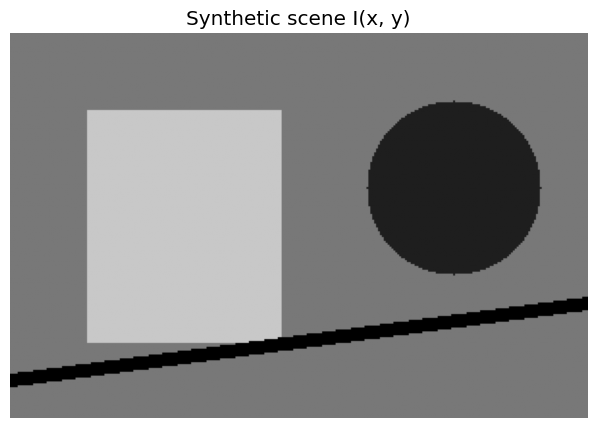

In [7]:
H, W = 200, 300
scene = np.full((H, W), 120, dtype=np.uint8)          # grey background
cv2.rectangle(scene, (40, 40), (140, 160), 200, -1)   # bright rectangle  = 'house'
cv2.circle(scene, (230, 80), 45, 30, -1)              # dark circle        = 'sun'
cv2.line(scene, (0, 180), (300, 140), 0, 6)           # black line         = 'road'

print("shape:", scene.shape, "| dtype:", scene.dtype)
print("min:", scene.min(), "| max:", scene.max(), "| mean: %.2f" % scene.mean())

plt.imshow(scene, cmap='gray', vmin=0, vmax=255)
plt.title("Synthetic scene I(x, y)"); plt.axis('off'); plt.show()



### 🛠️ Task 1 — Point-wise transforms 
Complete the two functions below.

* **Inversion** (photographic negative): $I' = 255 - I$.
* **Brightness shift**: $I' = \mathrm{clip}(I + b,\ 0,\ 255)$.

Then run the verification cell and make sure **both assertions pass**.



In [ ]:
def invert_image(img):
    """Return the photographic negative of img (uint8)."""
    I2 = 0
    I2 = 255 -img
    pass


def shift_brightness(img, b):
    """Return img whose brightness is shifted by b, clipped to [0, 255]."""
    # ==== YOUR CODE HERE ====
    pass


# ---- visual check ---------------------------------------------------------
inv = invert_image(scene)
brt = shift_brightness(scene, 60)

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].imshow(scene, cmap='gray', vmin=0, vmax=255); ax[0].set_title("original"); ax[0].axis('off')
ax[1].imshow(inv,   cmap='gray', vmin=0, vmax=255); ax[1].set_title("inverted"); ax[1].axis('off')
ax[2].imshow(brt,   cmap='gray', vmin=0, vmax=255); ax[2].set_title("+60 brightness"); ax[2].axis('off')
plt.tight_layout(); plt.show()



In [ ]:
# ✅ Self check — do not edit
assert invert_image(np.array([0, 128, 255], dtype=np.uint8)).tolist() == [255, 127, 0], \
    "invert_image is wrong: it must compute 255 - img"
assert shift_brightness(np.array([0, 250], dtype=np.uint8), 30).tolist() == [30, 255], \
    "shift_brightness must clip to [0, 255]"
print("✅ Task 1 assertions passed!")



### 🛠️ Task 2 — Colour channels 
A colour image has 3 channels. Create a **red** patch and a **green** patch on a
black background (remember: OpenCV stores **BGR**). Print the mean value of each
channel of the red patch.



In [ ]:
colour = np.zeros((120, 200, 3), dtype=np.uint8)
# draw a red rectangle (BGR!) and a green rectangle (BGR!)
# ==== YOUR CODE HERE ====


plt.imshow(cv2.cvtColor(colour, cv2.COLOR_BGR2RGB))
plt.title("BGR image shown as RGB"); plt.axis('off'); plt.show()

red_patch = colour[20:80, 20:120]      # just an example region - adapt to your drawing
print("mean B,G,R of the red region:", red_patch.reshape(-1, 3).mean(axis=0))



## Part 2 · Pinhole camera & perspective projection 

**Recap.** With the camera at the origin and the image plane at distance $f$ in front
of it, a 3-D point $(X,Y,Z)$ projects to

$$x = f\,\frac{X}{Z}, \qquad y = f\,\frac{Y}{Z}$$

This is *perspective* projection. In homogeneous coordinates the linear model is
$\lambda\,\tilde{\mathbf{x}} = \mathrm{diag}(f,f,1)\,[I\mid 0]\,\tilde{\mathbf{X}}$.

**Effects you should be able to explain:** objects shrink as $Z$ grows, parallel
lines converge to a vanishing point, and a real pinhole produces an *inverted*
image (we usually use a virtual plane at $+f$ to avoid flipping).



In [ ]:
def project_pinhole(points3d, f):
    """Project N 3-D points (N,3) with a pinhole camera of focal length f.

    Returns the 2-D coordinates (N,2) using x = f*X/Z, y = f*Y/Z.
    Points with Z <= 0 (behind the camera) must be dropped.
    """
    # ==== YOUR CODE HERE ====
    pass


# A few 3-D points at DIFFERENT depths
world = np.array([
    [1.0, 1.0, 5.0],     # near
    [1.0, 1.0, 10.0],    # far
    [0.0, 2.0, 8.0],
    [-1.0, -1.0, 4.0],
])
f = 50.0
px = project_pinhole(world, f)
print("projected 2-D points:\n", px)

# Is the far point really ~2x smaller than the near point?  (same X,Y, double Z)
near, far = px[0], px[1]
print("\nsame (X,Y), double Z -> x/y should halve.")
print("near (%.2f, %.2f)  far (%.2f, %.2f)" % (near[0], near[1], far[0], far[1]))



In [ ]:
# ✅ Self check — do not edit
_expected = np.array([[10., 10.], [5., 5.], [0., 12.5], [-12.5, -12.5]])
px = project_pinhole(world, f)
assert np.allclose(px, _expected), "project_pinhole output does not match hand calculation"
print("✅ Task 3 assertions passed — your projection is correct!")



### 📝 Task 3 — Conceptual questions
Answer concisely *in your own words*:

1. **Size scaling.** Two identical cars at depths $Z_1=5\,\mathrm{m}$ and $Z_2=10\,\mathrm{m}$
   are photographed. How many times smaller is the second car in the image? Why?
2. **Vanishing point.** You photograph straight railway tracks. The two rails are parallel
   in the world yet they meet in the image. Explain why (use $x=fX/Z$).
3. **Inversion.** Why is the image on the back wall of a camera obscura upside-down?
4. **Orthographic.** Write the orthographic-projection equations and state when it is a
   reasonable approximation of perspective.

> *Your answers (double-click to edit):*
> 1.
> 2.
> 3.
> 4.



In [ ]:
# Task 4 (small code): orthographic projection for comparison
def project_orthographic(points3d, s=1.0):
    """Orthographic projection: simply drop Z (scaled by s)."""
    # ==== YOUR CODE HERE ====
    pass

# Same world points, compare perspective (f=50) vs orthographic (s=50)
px_p = project_pinhole(world, 50.0)
px_o = project_orthographic(world, 50.0)

plt.figure(figsize=(10, 6))
plt.scatter(px_p[:, 0], -px_p[:, 1], c='red',  label='perspective', s=90, marker='o')
plt.scatter(px_o[:, 0], -px_o[:, 1], c='blue', label='orthographic', s=60, marker='x')
for i, txt in enumerate(range(len(world))):
    plt.annotate(txt, (px_p[i, 0], -px_p[i, 1]))
plt.gca().set_aspect('equal'); plt.grid(alpha=.3); plt.legend()
plt.title("Perspective vs orthographic (numbers = point index)")
plt.xlabel("x (px)"); plt.ylabel("-y (px)"); plt.show()
print("Perspective separates depths (varying size), orthographic does not.")



## Part 3 · Light & Lambertian shading *(optional recap)*

**Recap.** For a Lambertian (matte) surface the reflected intensity is
$I = k_d \max(0,\, \hat N\cdot \hat L)$, i.e. bright when the surface normal
$\hat N$ points toward the light $\hat L$. This is the simplest model of how a 3-D
shape produces a shaded 2-D image — the link between *geometry* and *pixels*.

Implement the dot-product shading for a synthetic sphere (its normals are already
computed for you).



In [ ]:
# normals of a sphere of radius r rendered on a grid
r = 60
yy, xx = np.mgrid[0:150, 0:150]
xc, yc = 75, 75
d2 = (xx - xc) ** 2 + (yy - yc) ** 2
inside = d2 <= r * r
Nz = np.sqrt(np.clip(r * r - d2, 0, None))
N = np.zeros((150, 150, 3))
N[..., 0] = (xx - xc) / r; N[..., 1] = (yy - yc) / r; N[..., 2] = Nz / r
N[~inside] = 0.0

def lambertian_shade(N, L):
    """Return intensity map k_d*max(0, N . L) with N,L unit vectors, k_d=1."""
    # hint: np.clip(np.einsum('ijk,k->ij', N, L), 0, None)
    # ==== YOUR CODE HERE ====
    pass

L1 = np.array([0.0, 0.0, 1.0])      # light straight from the front
L2 = np.array([1.0, 0.2, 0.8])      # light from the right
L2 = L2 / np.linalg.norm(L2)

fig, ax = plt.subplots(1, 2, figsize=(11, 5))
for a, L, t in zip(ax, (L1, L2), ("light from front", "light from upper-right")):
    a.imshow(lambertian_shade(N, L), cmap='gray'); a.set_title(t); a.axis('off')
plt.tight_layout(); plt.show()
print("Front-lit sphere looks flat/even; side-lit sphere shows shading gradient. ✅")



## Part 4 · Camera geometry: extrinsic → intrinsic → pixels 

**Recap.** Going from a *world* point $\mathbf{X}_w$ to a *pixel* $\mathbf{x}$ needs two
steps:

1. **Extrinsic** (where is the camera in the world?): rotate then translate
   $\mathbf{X}_c = R\,\mathbf{X}_w + t$
2. **Intrinsic** (from camera coordinates to pixels):
   $K=\begin{bmatrix} f_x & 0 & c_x\\ 0 & f_y & c_y\\ 0&0&1\end{bmatrix}$, and in
   homogeneous coordinates $\lambda\,\tilde{\mathbf{x}} = K\,[R\mid t]\,\tilde{\mathbf{X}}_w$.

Write the two helper functions, then compare your result with OpenCV's `projectPoints`.



In [ ]:
def extrinsic_transform(Xw, R, t):
    """World -> camera coordinates: Xc = R @ Xw + t.  Xw is (N,3)."""
    # ==== YOUR CODE HERE ====
    pass


def full_projection(Xw, K, R, t):
    """Pixel projection: x ~ K (R Xw + t).  Return (N,2) float pixel coords.

    Compute Xc = R Xw + t, then x = fx*Xc_x/Xc_z + cx, y = fy*Xc_y/Xc_z + cy.
    """
    # ==== YOUR CODE HERE ====
    pass


# ground-truth camera
K = np.array([[600., 0, 320], [0, 600., 240], [0, 0, 1.]])
R = cv2.Rodrigues(np.array([0.05, -0.1, 0.2]))[0]
t = np.array([0.1, -0.2, 6.0]).reshape(3, 1)

# a few world points on a flat plane z=0
Xw = np.array([[0, 0, 0], [1, 0, 0], [0, 1, 0], [0.5, 0.5, 0]], dtype=np.float64)
mine = full_projection(Xw, K, R, t)
ref, _ = cv2.projectPoints(Xw, cv2.Rodrigues(np.array([0.05, -0.1, 0.2]))[0],
                           t, K, np.zeros(5))
ref = ref.reshape(-1, 2)
print("mine:\n", np.round(mine, 2))
print("\nOpenCV:\n", np.round(ref, 2))
print("\nmax |difference| =", np.abs(mine - ref).max())



In [ ]:
# ✅ Self check — do not edit
Xw = np.array([[0, 0, 0], [1, 0, 0], [0, 1, 0], [0.5, 0.5, 0]], dtype=np.float64)
Rcv = cv2.Rodrigues(np.array([0.05, -0.1, 0.2]))[0]
tcv = np.array([0.1, -0.2, 6.0]).reshape(3, 1)
ref, _ = cv2.projectPoints(Xw, Rcv, tcv, K, np.zeros(5))
ref = ref.reshape(-1, 2)
assert np.allclose(full_projection(Xw, K, Rcv, tcv), ref, atol=1e-6), \
    "your full_projection does not match cv2.projectPoints"
print("✅ Task 5 assertions passed — matches OpenCV within 1e-6!")



## Part 5 · Camera calibration & distortion 

**Recap.** Calibration recovers $K$ (and distortion) from images of a known pattern
(checkerboard). Two classical routes:

* **DLT** — build the $2N\times 12$ matrix $A$ from the correspondences
  $u=\frac{P_{11}X+P_{12}Y+P_{13}Z+P_{14}}{P_{31}X+P_{32}Y+P_{33}Z+P_{34}}$ (and
  similarly for $v$), then $P$ is the last row of $V^\top$ in
  $\mathrm{SVD}(A)$.
* **`cv2.calibrateCamera`** — non-linear refinement of $K$, distortion and poses by
  minimising the **reprojection error**.

The first cell builds a **synthetic calibration rig**: it simulates 10 photos of a
checkerboard from random poses using a known ground-truth $K$. Run it, then complete
the two tasks.



In [ ]:
# ---- provided: synthetic calibration data (do not edit) -------------------
cb_size = (9, 6)          # inner corners
sq = 25.0                 # mm per square
objp = np.zeros((cb_size[0] * cb_size[1], 3), np.float32)
objp[:, :2] = np.mgrid[0:cb_size[0], 0:cb_size[1]].T.reshape(-1, 2) * sq

K_truth = np.array([[800., 0, 320], [0, 800., 240], [0, 0, 1]], dtype=np.float32)
dist_truth = np.array([0.05, -0.1, 0.001, 0.001, 0.02], dtype=np.float32)  # k1,k2,p1,p2,k3

np.random.seed(0)
obj_points, img_points = [], []
for _ in range(10):
    rvec, _ = cv2.Rodrigues(np.array([np.random.uniform(-.6, .6),
                                      np.random.uniform(-.6, .6),
                                      np.random.uniform(-.3, .3)], np.float32))
    tvec = np.array([[np.random.uniform(-40, 40)],
                     [np.random.uniform(-40, 40)],
                     [np.random.uniform(350, 650)]], np.float32)
    pts, _ = cv2.projectPoints(objp, rvec, tvec, K_truth, dist_truth)
    img_points.append((pts.reshape(-1, 2) + np.random.normal(0, .2, (len(objp), 2))).astype(np.float32))
    obj_points.append(objp)

print(f"Simulated {len(img_points)} checkerboard views. Ground-truth K:\n{K_truth}")



In [ ]:
# ---- TASK 6: implement the DLT calibration and compare with truth --------
def dlt_calibrate(points_3d, points_2d):
    """Estimate the 3x4 projection matrix P by DLT (see recap above)."""
    N = points_3d.shape[0]
    A = np.zeros((2 * N, 12))
    for i in range(N):
        X, Y, Z = points_3d[i]
        u, v = points_2d[i]
        A[2 * i]   = [X, Y, Z, 1, 0, 0, 0, 0, -u * X, -u * Y, -u * Z, -u]
        A[2 * i + 1] = [0, 0, 0, 0, X, Y, Z, 1, -v * X, -v * Y, -v * Z, -v]
    # P is the last row of V^T from the SVD of A
    # ==== YOUR CODE HERE ====
    pass


# ---- use your DLT on every view and measure reprojection error -----------
# (a pinhole model: it ignores lens distortion - compare later with cv2!)
errs = []
for obj, img in zip(obj_points, img_points):
    P = dlt_calibrate(obj, img)
    P = P / np.linalg.norm(P)                     # P is defined up to scale
    hom = np.hstack([obj, np.ones((len(obj), 1))])
    proj = (P @ hom.T).T
    proj = proj[:, :2] / proj[:, 2:3]             # dehomogenise
    errs.append(np.linalg.norm(proj - img, axis=1).mean())
print("P shape:", P.shape)
print(f"DLT mean reprojection error over all views: {np.mean(errs):.3f} px")



In [ ]:
# ---- TASK 7: use cv2.calibrateCamera on ALL views -------------------------
ret, mtx, dist, rvecs, tvecs = cv2.calibrateCamera(obj_points, img_points,
                                                  (640, 480), None, None)

print(f"✅ calibration RMS reprojection error = {ret:.4f} px")
print("Estimated K:\n", np.round(mtx, 1))
print("Ground-truth K:\n", K_truth)
rel = np.linalg.norm(mtx.astype(np.float64) - K_truth) / np.linalg.norm(K_truth)
print(f"Relative error on K = {rel:.5f}")
print("Estimated distortion:", np.round(dist.ravel(), 4))
print("Ground-truth distortion:", dist_truth)



### 📝 Task 8 — Interpreting the calibration 
1. Why do we need **several views** of the checkerboard taken from *different angles*
   instead of one frontal view?
2. What does the **RMS reprojection error** tell us about the calibration quality?
   What value do we hope to see (in pixels)?
3. Which intrinsic parameters live on the **diagonal** of $K$, and which ones are the
   *principal point* offsets? Where should the principal point be for a $640\times480$
   sensor that is perfectly centred?

> *Your answers (double-click to edit):*
> 1.
> 2.
> 3.



In [ ]:
# ---- TASK 9 (extra): distortion correction demo ---------------------------
# Build a clean synthetic checkerboard image
h, w = 480, 640
board = np.full((h, w), 255, dtype=np.uint8)
s = 40
for i in range(0, h, s):
    for j in range(0, w, s):
        if (i // s + j // s) % 2 == 0:
            board[i:i + s, j:j + s] = 0

# strong barrel distortion coefficients for a *visible* effect
dist_barrel = np.array([0.6, -0.5, 0, 0, 0], dtype=np.float32)
distorted = cv2.undistort(board, K_truth, dist_barrel)          # apply distortion
corrected = cv2.undistort(distorted, mtx, -dist_barrel)          # undo it (approx.)

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].imshow(board, cmap='gray');     ax[0].set_title("original");      ax[0].axis('off')
ax[1].imshow(distorted, cmap='gray'); ax[1].set_title("barrel-distorted"); ax[1].axis('off')
ax[2].imshow(corrected, cmap='gray'); ax[2].set_title("undistorted");    ax[2].axis('off')
plt.tight_layout(); plt.show()
print("Negative k1 -> barrel distortion; passing the negated coefficients removes it. ✅")



## ✅ Lab 1 — Submission checklist

Before submitting, make sure you have:
- [ ] Run **every** cell (menu: *Run All*) so outputs are saved in the notebook.
- [ ] Completed **Tasks 0–9**: filled in your code (`# ==== YOUR CODE HERE ====`) and written
      your conceptual answers in the markdown boxes.
- [ ] All `Self check` cells print `✅ ... passed!`.
- [ ] Saved and uploaded `Lab1_Image_Formation_and_Camera_Geometry.ipynb`.

### 🔎 Reflection (1 line each)
- What part of the pipeline (formation → geometry → calibration) do you understand best?
- What confused you the most? Write one question you would ask in the lab workshop.

> *Your reflection:*

